# Quiz 1：資料集準備（10 分）

**蘇芯儀 / Sharon0726**

三種任務的來源、切分、前處理及實例。訓練與下載程式在 `quiz2_sentiment.py`、`quiz3_vision.py`、`quiz4_caption.py`，完整 GPU 流程為 `MMIP_Week4_Colab.ipynb`。

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
R=Path('results')
assert R.exists(), 'Run from Week4; results/ is required.'
def read(name): return json.loads((R/name).read_text(encoding='utf-8'))
def show(name): display(Image(filename=str(R/'figures'/name)))


## 1. 情感分類資料（3 分）

[Rotten Tomatoes](https://huggingface.co/datasets/cornell-movie-review-data/rotten_tomatoes)：英文影評，negative=0、positive=1。保留官方切分，去除正規化後的相同句子，字典只取 train；截斷至 64 tokens 並 padding。

In [2]:
display(read('sentiment_data.json'))
display(pd.read_csv(R/'sentiment_split.csv').groupby(['split','label']).size().unstack())
display(pd.read_csv(R/'predictions/sentiment_lstm.csv')[['text','true']].head(6))

{'source': 'cornell-movie-review-data/rotten_tomatoes',
 'fingerprints': {'train': '0346a9d2308d9056',
  'validation': '4d310508c191379e',
  'test': '23aa2ff3ad95b6f5'},
 'counts': {'test': 1066, 'validation': 1066, 'train': 8530},
 'vocab_size': 12000,
 'labels': {'0': 'negative', '1': 'positive'},
 'deduplication': 'normalized exact text; test > validation > train'}

label,0,1
split,,
test,533,533
train,4265,4265
validation,533,533


,text,true
0,lovingly photographed in the manner of a golde...,1
1,consistently clever and suspenseful .,1
2,"it's like a "" big chill "" reunion of the baade...",1
3,the story gives ample opportunity for large-sc...,1
4,"red dragon "" never cuts corners .",1
5,fresnadillo has something serious to say about...,1


## 2. 影像分類資料（4 分）

[CIFAR-10 官方來源](https://www.cs.toronto.edu/~kriz/cifar.html)，使用 [UofT HF 鏡像](https://huggingface.co/datasets/uoft-cs/cifar10)。train/val 每類 1,000/200，其餘 train 不使用；test 為完整官方 10,000 張。模型輸入 resize 到 224×224，只有 train 隨機左右翻轉。

{'source': 'uoft-cs/cifar10',
 'fingerprints': {'train': 'dc9b490412f5c250', 'test': 'bab4620c7501a3e6'},
 'counts': {'train': 10000, 'validation': 2000, 'test': 10000},
 'classes': ['airplane',
  'automobile',
  'bird',
  'cat',
  'deer',
  'dog',
  'frog',
  'horse',
  'ship',
  'truck'],
 'selection': 'seeded class-balanced subset for train/val; full official test',
 'train_unused': 38000,
 'pretraining': {'vit': 'ImageNet-21k then ImageNet-1k',
  'resnet': 'ImageNet-1k'}}

label,0,1,2,3,4,5,6,7,8,9
split,,,,,,,,,,
test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
train,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
validation,200,200,200,200,200,200,200,200,200,200


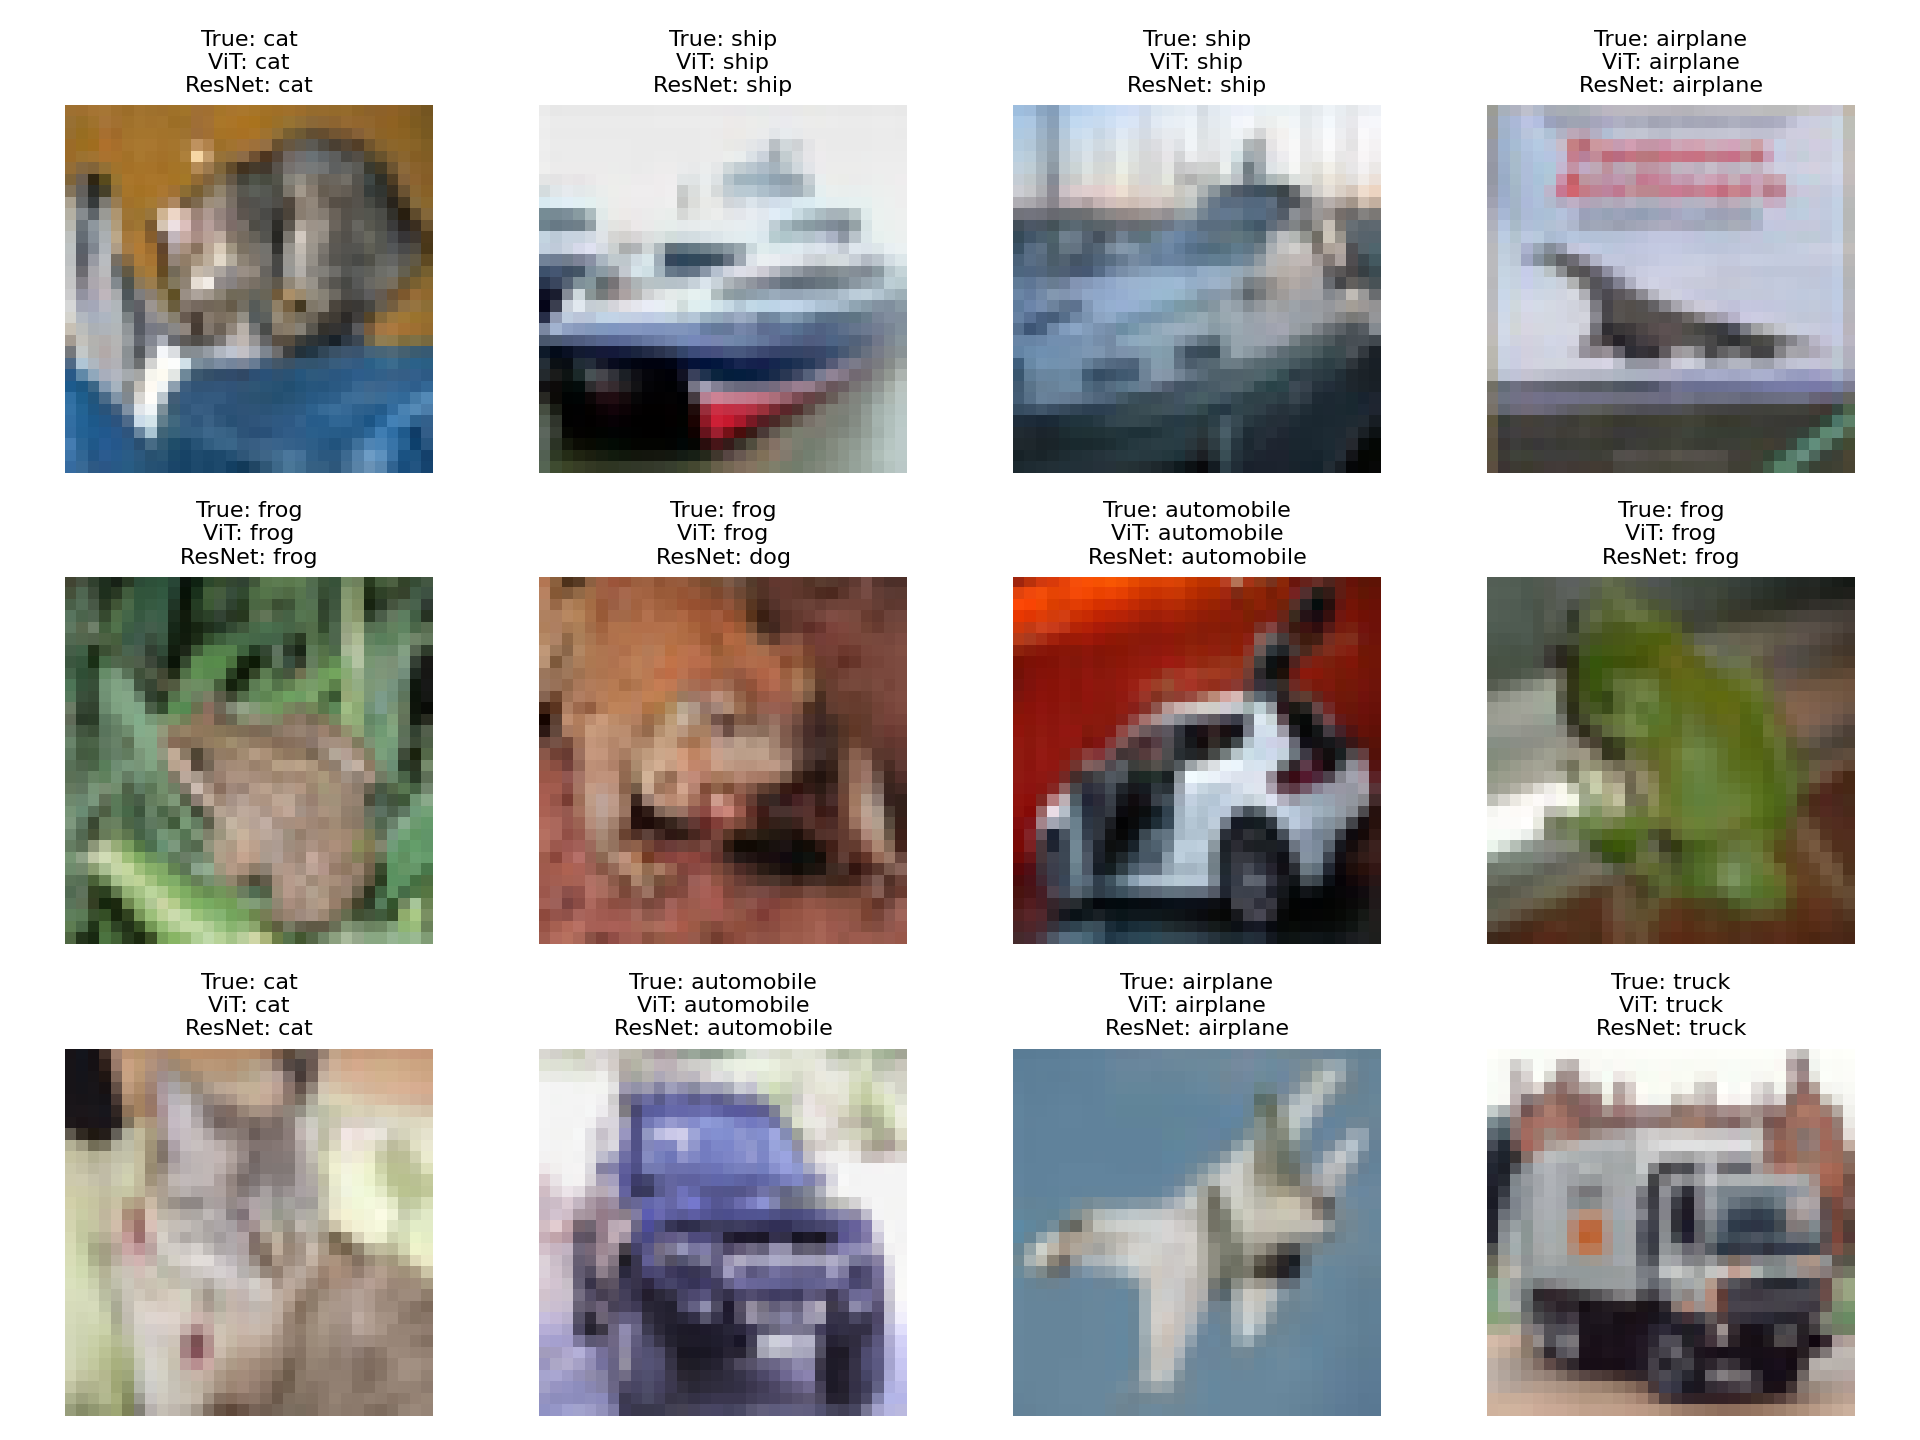

In [3]:
display(read('vision_data.json'))
display(pd.read_csv(R/'vision_split.csv').groupby(['split','label']).size().unstack())
show('vision_examples.png')

## 3. 影像文字配對資料（3 分）

[Flickr8k](https://huggingface.co/datasets/tsystems/flickr8k)：先以影像 ID 切 train/val/test，再展開每張的多個 caption；不讓同圖不同 caption 跨集合。自訂 seed=42 切分，非官方 Karpathy split。只由 train 建字典，長度 32 含 BOS/EOS。

{'source': 'tsystems/flickr8k',
 'fingerprint': '9b1bbaa48e4888f2',
 'counts': {'train': 6000, 'validation': 1000, 'test': 1091},
 'caption_counts': {'train': 30000, 'validation': 5000, 'test': 5455},
 'vocab_size': 6000,
 'split': 'custom seed-42 image-level 6000/1000/remainder; NOT official Karpathy split',
 'encoder': 'ResNet18 ImageNet1K_V1, frozen',
 'max_length_including_bos_eos': 32}

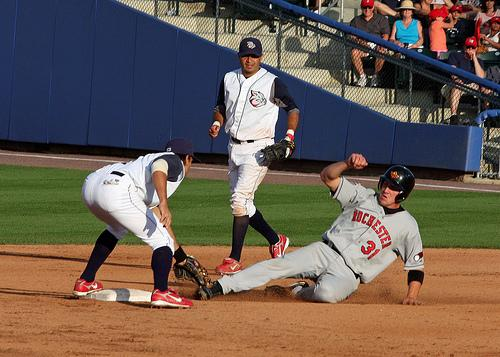

['A baseball player is tagged out sliding into second base .',
 'A baseball player slides toward a base .',
 'a man in a grey uniform sliding into a base',
 'Three men playing baseball .',
 'two fielder are defending the base as a member of the batting team slide towards it .']

In [4]:
display(read('caption_data.json'))
case=read('gemini_cases.json')[0]
show('caption_sample_1.jpg')
display(case['references'])

## 資料分離檢查

In [5]:
s=pd.read_csv(R/'sentiment_split.csv'); assert s.sha256.is_unique
v=pd.read_csv(R/'vision_split.csv'); assert not set(v.query('split == "train"').source_id) & set(v.query('split == "validation"').source_id)
c=pd.read_csv(R/'caption_split.csv'); assert c.filename.is_unique
print('PASS: normalized text and image IDs do not cross partitions.')

PASS: normalized text and image IDs do not cross partitions.
